# **MODULE 13 — AUDIO ENHANCEMENT & RESTORATION 🎧**



Core audio-processing concept

Important for Speech AI



In Module 11, we learned how noise affects speech recordings. In Module 12, we learned how digital filters modify frequency components.

Now we're going one step further: **how do we improve the overall quality of a poor audio recording?**

Imagine recording a voice message:

- The speaker is too quiet.
- A fan creates continuous background noise.
- The room produces an echo.
- Some portions are much louder than others.
- The recording has unwanted frequency components.

We can use audio enhancement and restoration techniques to improve the recording.

The central goal is:

> Improve the quality and intelligibility of audio while preserving the original speech as accurately as possible.

These techniques are important in:

- Automatic Speech Recognition (ASR).
- Speech-to-text systems.
- Voice assistants.
- Meeting transcription.
- Call-center recordings.
- Podcast and video restoration.
- Speech communication systems.

## **13.1 Audio Enhancement vs Audio Restoration**

These terms are related, but they have slightly different emphases.

**Audio enhancement** aims to improve the perceived or measurable quality of an audio signal.

Examples:

- Reducing background noise.
- Improving speech clarity.
- Balancing volume.
- Reducing reverberation.

**Audio restoration** focuses on recovering or repairing degraded recordings.

Examples:

- Removing persistent hum.
- Repairing clicks and pops.
- Reducing recording noise.
- Correcting certain distortions.

In practice, the two overlap.

A useful mathematical model is:

\\[ y[n]=s[n]+n[n] \\]

Where:

- \\(y[n]\\) = Degraded recording.
- \\(s[n]\\) = Desired original speech.
- \\(n[n]\\) = Added unwanted noise.

Our objective is to estimate:

\\[ \hat{s}[n]\approx s[n] \\]

Here, \\(\hat{s}[n]\\) is the enhanced speech.

**Important:** The original clean signal is usually unknown in real-world restoration. Enhancement algorithms estimate it; they cannot guarantee perfect recovery.

## **13.2 Audio Normalization**

Normalization is the process of adjusting audio levels according to a selected target.

Imagine two recordings:

- Recording A has a peak amplitude of 0.9.
- Recording B has a peak amplitude of 0.2.

Even if the speaker's actual performance is similar, recording B may sound much quieter.

Normalization can adjust their levels.

There are different types of normalization, and they do not all do the same thing.

## **13.3 Peak Normalization**

Peak normalization adjusts the entire recording so that its highest absolute sample reaches a chosen target peak.

The formula is:

\\[ x\_{\text{normalized}}[n] = x[n]\frac{A\_{\text{target}}}{A\_{\text{peak}}} \\]

Where:

\\[ A\_{\text{peak}}=\max_n |x[n]| \\]

- \\(x[n]\\) = Original signal.
- \\(A\_{\text{target}}\\) = Desired peak amplitude.
- \\(A\_{\text{peak}}\\) = Original peak amplitude.

### **Example**

Suppose:

\\[ A\_{\text{peak}}=0.5 \\]

And our target peak is:

\\[ A\_{\text{target}}=0.9 \\]

The gain factor is:

\\[ G=\frac{0.9}{0.5}=1.8 \\]

Every sample is multiplied by 1.8.

The resulting peak amplitude becomes 0.9.

![無料ソフトAudacityでノーマライズをする方法【音量・音圧UP！】 | Vook(ヴック)](https://images.openai.com/static-rsc-4/VCB9QSEzuHEaXi3eVHadxuuafcMceOBB2mJdlwKrDt7gQr8w_KuuyqIFW8bxMcHzVCyP7gUFU0F0upAxF7yBE1pxmV1xS03Bq5u0X0eXQgbhcZ8cPoAIMbDqYXGWlaMZPHLo1Auw6asPvyqjn3avmxIQgyeWtFgYa9JRLkAzXoQ?purpose=inline)

[vook.vc](https://vook.vc/n/5359?utm_source=chatgpt.com)

### **Python implementation**

```
import numpy as npdef peak_normalize(audio, target_peak=0.9):    peak = np.max(np.abs(audio))    if peak == 0:        return audio.copy()    return audio * (target_peak / peak)
```

Usage:

```
normalized_audio = peak_normalize(    audio,    target_peak=0.9)
```

### **Limitation**

Peak normalization does not remove background noise.

It amplifies the speech and the noise together.

If the recording contains loud background noise, peak normalization can make that noise louder too.

## **13.4 RMS Normalization**

Peak normalization considers only the highest amplitude sample.

But that doesn't tell us the average signal level.

For that, we use RMS normalization.

RMS stands for Root Mean Square.

\\[ RMS=\sqrt{\frac{1}{N}\sum\_{n=0}^{N-1}x[n]^2} \\]

RMS provides a measure of the signal's average magnitude in a mathematical sense.

### **RMS normalization formula**

\\[ x\_{\text{normalized}}[n] = x[n]\frac{RMS\_{\text{target}}}{RMS\_{\text{original}}} \\]

Where:

- \\(RMS\_{\text{original}}\\) = Original RMS.
- \\(RMS\_{\text{target}}\\) = Desired RMS.

### **Example**

Suppose:

\\[ RMS\_{\text{original}}=0.1 \\]

And:

\\[ RMS\_{\text{target}}=0.2 \\]

Then:

\\[ G=\frac{0.2}{0.1}=2 \\]

The entire recording is multiplied by 2.

![Mastering Trends For 2023](https://images.openai.com/static-rsc-4/eakIpMpmYD4u6gsl2xBnd1BoAvnqEFqEyRf7rcg5anRoSn1P1p_FZNTv5eiDQKFauabSTCw_FS2-_5UCijQ2f00qhKg1Xp4gzytHmbzuUBLNsNKqmxJnTncm3zMuWmmYSBe55XrLoON__CTPviNeblaqm1FoZ0tWvOU-YQSvJkc?purpose=inline)

[masteringthemix.com](https://www.masteringthemix.com/blogs/learn/mastering-trends-for-2023?utm_source=chatgpt.com)

### **Python implementation**

```
def rms_normalize(audio, target_rms=0.1):    rms = np.sqrt(np.mean(audio ** 2))    if rms == 0:        return audio.copy()    return audio * (target_rms / rms)
```

### **Peak vs RMS Normalization**

| Feature                          | Peak normalization      | RMS normalization           |
| -------------------------------- | ----------------------- | --------------------------- |
| Based on                         | Maximum absolute sample | Average squared amplitude   |
| Main purpose                     | Control peak level      | Adjust average signal level |
| Considers loudness distribution? | No                      | Partly, through RMS         |
| Removes noise?                   | No                      | No                          |
| Can amplify noise?               | Yes                     | Yes                         |

**Important:** RMS is not the same as perceived loudness. Human loudness perception depends on frequency, duration and listening conditions.

## **13.5 Loudness Normalization**

Loudness normalization adjusts audio according to a standardized estimate of perceived loudness.

Unlike simple peak or RMS normalization, loudness measurement takes human hearing characteristics into account.

A common unit is:

**LUFS — Loudness Units relative to Full Scale.**

It is widely used in broadcasting, streaming and audio production.

For example, two recordings may have:

- Similar peak levels.
- Different perceived loudness.

Loudness normalization helps make their perceived playback levels more consistent.

![What is the Loudness War & Is it Still Relevant in 2025?](https://images.openai.com/static-rsc-4/HIS88s-LccmKW_-AkH9sOsKqEQWdGwza6zpVDA1zlpoogAbR1Sx_N3_W7RrkpnermJhdDfvnXPmzp--OGNzl8WL3QGNc9Zw3b64ULusrE4jGultADW5ptqBtrQ318gJmMWVWcSCib3QbWZkKGdJwsjeDE_PDFY7WfXPDddlsj3o?purpose=inline)

[unison.audio](https://unison.audio/loudness-war/?utm_source=chatgpt.com)

### **Important distinction**

| Normalization | What it targets              |
| ------------- | ---------------------------- |
| Peak          | Maximum sample amplitude     |
| RMS           | Average signal level         |
| Loudness      | Estimated perceived loudness |

Loudness normalization does not automatically improve the signal-to-noise ratio. It adjusts level, not the separation between speech and noise.

## **13.6 Dynamic Range**

Dynamic range describes the difference between the quietest and loudest meaningful signal levels.

In audio, a recording with a large dynamic range may contain:

- Very quiet speech.
- Moderate speech.
- Very loud speech.

![Why Are My Mixes So Quiet?](https://images.openai.com/static-rsc-4/aKjsqwm1nbRZFqq0ry55UjkIjFolqQQoCA_l1Y1HQHIUgohWH5rO5CRyeZRFa6c_HflApU8RdXsF0iW8YgFU0U_gb1jIMx6JX4oeJRY179EX_74X12mVPeYED41ctqS6nfrBnGTxCd1u9TYSVLZzgoVTEo_vgjqThfbopHWcjKg?purpose=inline)

[stevenmeloneyrecording.com](https://www.stevenmeloneyrecording.com/post/why-are-my-mixes-so-quiet?utm_source=chatgpt.com)

### **Example**

Imagine a speaker recording a sentence:

- First sentence: Very quiet.
- Second sentence: Normal volume.
- Third sentence: Shouting.

The recording has a wide range of amplitudes.

If we want the recording to have more consistent levels, we can use dynamic-range processing.

### **Dynamic-range compression**

A compressor reduces the difference between loud and quiet sections by reducing gain above a selected threshold.

For example:

- Quiet speech remains relatively unchanged.
- Loud speech is reduced.
- The output becomes more consistent.

Common compressor parameters:

- Threshold.
- Ratio.
- Attack time.
- Release time.
- Makeup gain.

**Don't confuse compression with normalization.** Normalization applies gain to a recording or segment; dynamic-range compression changes gain depending on signal level.

## **13.7 Noise Reduction**

Noise reduction attempts to suppress unwanted components while preserving useful speech.

Recall our noisy audio model:

\\[ y[n]=s[n]+n[n] \\]

We want:

\\[ \hat{s}[n]\approx s[n] \\]

A noise-reduction system estimates which components are likely to belong to noise and attenuates them.

![Single-channel speech enhancement using implicit Wiener filter for high-quality speech communication | International Journal of Speech Technology | Springer Nature Link](https://images.openai.com/static-rsc-4/obAtx0ZdDfQ6ZYVXO5JmTGC7t2SCxzCBgFgKxM_9VMB40wrCK7oS-vwHTR69Ndl21l7bzvxol4fC-DmI7zvRHPH2YBaeZoK9IHjWbiZajgyyyZ7V4uijzs7afQghM2XyBp1fC3rpOA45yqpJiHHuR__874ML5Oqo5vn6z_2Umx8?purpose=inline)

[link.springer.com](https://link.springer.com/article/10.1007/s10772-022-09987-4?utm_source=chatgpt.com)

Examples:

- Fan noise reduction.
- Electrical hum reduction.
- Microphone hiss suppression.
- Traffic noise suppression.

Noise reduction is not always perfect because speech and noise can occupy the same frequency regions.

## **13.8 Spectral Subtraction**

We introduced spectral subtraction in Module 11. Now let's understand how it fits into audio enhancement.

Spectral subtraction works in the frequency domain.

### **Basic principle**

1. Divide audio into short frames.
2. Calculate the STFT.
3. Estimate the background-noise spectrum.
4. Subtract the estimated noise magnitude from the noisy spectrum.
5. Reconstruct the enhanced audio using the inverse STFT.

A simplified equation is:

\\[ |\hat{S}(m,k)| = \max\left( |Y(m,k)|-\alpha|\hat{N}(k)|,\ 0 \right) \\]

Where:

- \\(Y(m,k)\\) = Noisy speech STFT.
- \\(\hat{N}(k)\\) = Estimated noise magnitude.
- \\(\alpha\\) = Noise subtraction strength.
- \\(\hat{S}(m,k)\\) = Estimated clean speech magnitude.

![AudioLDM: Revolutionizing Text-to-Audio Generation Quality - Markovate](https://images.openai.com/static-rsc-4/91b8fYj3OO5l_qwBYSXZf1fRbb9pRZXUVrLmqFiYmNIWfvlT_FuEDh_AsFcKyUv_Md4-eReU3eyxdpgT23VPwTGfUar_XJYu2KB2425WnQCSDZMvq8CVOTYj2ndslxvZikthD5-mZwxDxrIbH59usZf8qFJDlVFWZuwfdLef8iU?purpose=inline)

[markovate.com](https://markovate.com/blog/audioldm/?utm_source=chatgpt.com)

### **Why do we need noise estimation?**

Suppose we have a recording that begins with one second of silence before the speaker starts.

We can use that initial segment to estimate the background noise.

This is called a *noise-only segment*.

The estimate can then be applied to subsequent speech frames, assuming the noise characteristics remain reasonably stable.

### **Limitation**

If the noise estimate is inaccurate or subtraction is too aggressive, the output can contain:

- Musical noise.
- Metallic-sounding artifacts.
- Distorted consonants.
- Missing speech details.

This is one reason why modern enhancement systems often use more sophisticated statistical or deep-learning approaches.

## **13.9 Filtering-Based Enhancement**

Filtering-based enhancement uses digital filters to attenuate unwanted frequency components.

This connects directly to Module 12.

| Noise problem                        | Possible filter |
| ------------------------------------ | --------------- |
| Low-frequency wind rumble            | High-pass       |
| High-frequency hiss                  | Low-pass        |
| Narrow 50 Hz electrical hum          | Notch           |
| Noise outside a selected speech band | Band-pass       |

For example, a high-pass filter may reduce low-frequency wind noise.

But filtering has an important limitation:

**If noise and speech overlap in frequency, a filter may remove useful speech along with the noise.**

That is why filter selection should depend on the recording and the type of noise.

## **13.10 Reverberation Reduction**

In Module 11, we learned that reverberation is caused by sound reflections.

Consider someone speaking in a large empty room.

The microphone captures:

- Direct speech.
- Early reflections.
- Late reflections.

A simplified model is:

\\[ y(t)=s(t)\*h(t) \\]

Where:

- \\(s(t)\\) = Original speech.
- \\(h(t)\\) = Room impulse response.
- \\(y(t)\\) = Recorded reverberant speech.

Reverberation reduction attempts to reduce the unwanted room reflections.

![Speech Data Augmentation : \[Audio/Speech Processing Part 2\] | by Leonard Loo | Medium](https://images.openai.com/static-rsc-4/p41V8_twP4-T2omb1dJd2-sYra7vrXYZk7vXy1P5HGWphxR9DDmbEoQEdbDuIho4TuTs1jX6Cu_H0CjLXHPwcPXHThAWXsFZq-9xerllO-saDG7kdIMlFkVFm9U_pG8SwiP5JIrtT0CAawu8e4xiIgC9srMlE3gxvLsV47CMIok?purpose=inline)

[leonardloo.medium.com](https://leonardloo.medium.com/part-2-audio-speech-processing-speech-data-augmentation-463dac823a8d?utm_source=chatgpt.com)

### **What can reverberation reduction improve?**

- Speech clarity.
- Word intelligibility.
- Speaker separation.
- ASR performance in reverberant environments.

## **13.11 Dereverberation**

Dereverberation is the process of estimating and reducing reverberation from an audio recording.

The objective is to obtain an approximation of the original direct speech:

\\[ \hat{s}(t)\approx s(t) \\]

### **Common conceptual approaches**

**1. Inverse filtering**

If the room impulse response is known or estimated, an inverse filter can attempt to undo its effect.

**2. Statistical dereverberation**

Uses statistical properties of reverberant speech to estimate and suppress late reflections.

**3. Multichannel dereverberation**

Uses recordings from multiple microphones to exploit spatial information.

**4. Deep-learning-based dereverberation**

Neural networks learn to transform reverberant speech into cleaner-sounding speech using training examples.

### **Noise reduction vs Dereverberation**

| Noise reduction                             | Dereverberation                            |
| ------------------------------------------- | ------------------------------------------ |
| Targets unwanted noise                      | Targets room reflections                   |
| Often models noise as an additive component | Often models room acoustics as convolution |
| Examples: fan, hiss, traffic                | Examples: echoing room, hall               |
| Can use noise spectrum estimation           | Can use room-response estimation           |

These problems can occur together, and a complete enhancement system may need to address both.

## **13.12 Speech Enhancement vs Noise Suppression**

These terms are closely related, but speech enhancement is the broader objective.

**Speech enhancement** attempts to improve speech quality by addressing one or more degradations.

It may include:

- Noise reduction.
- Dereverberation.
- Level adjustment.
- Speech clarity improvement.
- Artifact reduction.

**Noise suppression** specifically targets unwanted noise.

![GitHub - chenwj1989/python-speech-enhancement: a python library for speech enhancement · GitHub](https://images.openai.com/static-rsc-4/qp3HZ8LTZQSw1rt2wdYGJhO9yLEEFPtENH5f9t7aYgwT1L43mw3fX9qVeMmkhwamIi9qC21Ek2rzIiiOkdqkHKlcusvN9RHU5kR8mTneepPRsOYeGDqH6x3Yq2BSJl4pV9bft4FHc-jLbbJaF5Igb3yWlmXZGS0I5_otxI9j24M?purpose=inline)

[github.com](https://github.com/chenwj1989/python-speech-enhancement?utm_source=chatgpt.com)

| Feature                    | Speech enhancement     | Noise suppression     |
| -------------------------- | ---------------------- | --------------------- |
| Scope                      | Broad                  | More specific         |
| Main objective             | Improve speech quality | Reduce unwanted noise |
| Can address reverberation? | Yes                    | Not necessarily       |
| Can include normalization? | Yes                    | Not necessarily       |
| Can include denoising?     | Yes                    | Yes                   |

In practical systems, noise suppression is often one component of a larger speech-enhancement pipeline.

## **13.13 Limitations of Audio Enhancement**

Audio enhancement is powerful, but it has limitations.

Imagine a recording where:

- Speech is extremely quiet.
- Noise is very loud.
- Important consonants are masked.
- The microphone is overloaded.
- The audio is heavily clipped.

Can an enhancement algorithm recover everything?

No.

The original information may be lost or too weak to estimate reliably.

Some important limitations:

1. **Overlapping frequencies:** Speech and noise can occupy the same frequency regions.
2. **Low SNR:** When noise dominates, recovering the original speech becomes difficult.
3. **Clipping:** Severe clipping destroys information about the original waveform peaks.
4. **Reverberation:** Removing reflections without damaging direct speech can be difficult.
5. **Non-stationary noise:** Noise that changes rapidly is harder to estimate.
6. **Model limitations:** Enhancement models may perform poorly on unfamiliar microphones, environments, accents or noise types.

A good enhancement algorithm should improve useful speech information without unnecessarily changing the original voice.

## **13.14 Artifacts Introduced by Denoising**

A denoising algorithm can introduce new unwanted sounds or distortions. These are called **enhancement artifacts**.

![BLOG | Samsung Research](https://images.openai.com/static-rsc-4/Gaku2Qgh3pKB3hMxwZ5SymNkzZgF9tYuJjtdVvIei_GBZf7Om4nE3Hn34V8Dhe_ZXUP0kPApUhPz7SdK1WGyErhIY6bZCSGcV25eqynIFaT3P4zpAb3s2gYd57pPvfd2iuHyvhGELIJ6cOCIbt8pFK0L3jBiEzrqHsTYtXPtmfU?purpose=inline)

[research.samsung.com](https://research.samsung.com/blog/-INTERSPEECH-2025-A-Lightweight-Hybrid-Dual-Channel-Speech-Enhancement-System-under-Low-SNR-Conditions?utm_source=chatgpt.com)

Common artifacts:

| Artifact          | What it sounds or looks like                  |
| ----------------- | --------------------------------------------- |
| Musical noise     | Random tonal or bird-like sounds              |
| Metallic sound    | Artificial, robotic voice quality             |
| Speech smearing   | Speech details become blurred                 |
| Consonant loss    | Sounds such as /s/, /f/ become weaker         |
| Pumping           | Background noise level fluctuates unnaturally |
| Speech distortion | Voice sounds unnatural or altered             |

### **Why do artifacts occur?**

- Too much noise suppression.
- Incorrect noise estimation.
- Aggressive spectral subtraction.
- Poor model generalization.
- Excessive filtering.

**Important lesson:** The quietest output is not necessarily the best output.

A good enhancement system balances noise reduction with speech preservation.


## **What You Should Remember**

1. Peak normalization adjusts the maximum sample amplitude; RMS normalization adjusts average signal level.
2. Loudness normalization uses a perceptual loudness measurement such as LUFS.
3. Dynamic-range compression controls differences between quiet and loud sections.
4. Noise reduction attempts to suppress unwanted components while preserving speech.
5. Spectral subtraction estimates and subtracts background-noise magnitude.
6. Dereverberation targets room reflections rather than ordinary additive noise.
7. Aggressive enhancement can introduce musical noise, metallic sounds and lost consonants.
8. Objective measurements and human listening should be used together to evaluate enhancement quality.

## **Interview Questions**

1. What is audio enhancement?
2. What is the difference between peak normalization and RMS normalization?
3. What is LUFS?
4. What is dynamic range?
5. What is the difference between normalization and compression?
6. Explain spectral subtraction.
7. How does noise estimation work?
8. What is dereverberation?
9. What is the difference between noise suppression and speech enhancement?
10. What are musical-noise artifacts?
11. Why can an enhanced recording have a higher SNR but still sound unnatural?
12. How would you evaluate a speech-enhancement system?

---

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import soundfile as sf

from scipy.signal import stft, istft

from IPython.display import Audio, display

In [2]:
clean_speech, fs = sf.read("audio/raw/sample-speech-1m.mp3")

if clean_speech.ndim == 2:
    clean_speech = clean_speech.mean(axis=1)

clean_speech = clean_speech.astype(np.float64)

start = 5 * fs 
end = 15 * fs

clean_speech = clean_speech[start:end]

print("Sampling rate:", fs)
print("Number of samples:", len(clean_speech))
print("Duration:", len(clean_speech) / fs)

Sampling rate: 22050
Number of samples: 220500
Duration: 10.0


In [3]:
# Normalization
peak = np.max(np.abs(clean_speech))

if peak > 0:
    clean_speech = clean_speech * (0.5 / peak)

In [4]:
display(Audio(clean_speech, rate=fs))

In [5]:
# background noise 
np.random.seed(42)

noise = np.random.normal(
    loc=0,
    scale=1,
    size=len(clean_speech)
)

In [6]:
def add_noise_at_snr(clean, noise, target_snr_db):

    signal_power = np.mean(clean ** 2)
    noise_power = np.mean(noise ** 2)

    target_snr_linear = 10 ** (target_snr_db / 10)

    required_noise_power = (
        signal_power / target_snr_linear
    )

    scaled_noise = noise * np.sqrt(
        required_noise_power / noise_power
    )

    noisy = clean + scaled_noise

    return noisy, scaled_noise

In [7]:
noisy_speech, added_noise = add_noise_at_snr(
    clean_speech,
    noise,
    target_snr_db=10
)

In [8]:
print("Original speech")
display(Audio(clean_speech, rate=fs))

print("Noisy speech")
display(Audio(noisy_speech, rate=fs))

Original speech


Noisy speech


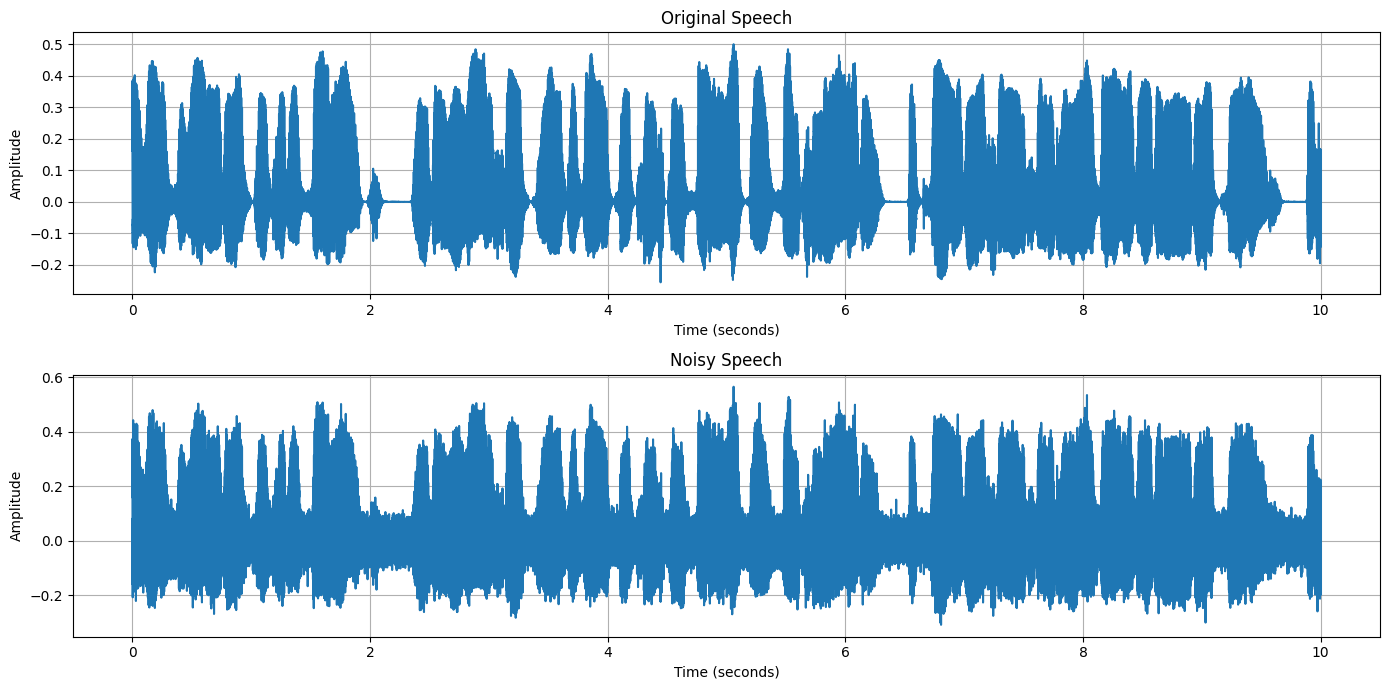

In [9]:
time = np.arange(len(clean_speech)) / fs

fig, axes = plt.subplots(
    2, 1,
    figsize=(14, 7)
)

axes[0].plot(time, clean_speech)

axes[0].set_title("Original Speech")
axes[0].set_xlabel("Time (seconds)")
axes[0].set_ylabel("Amplitude")
axes[0].grid()

axes[1].plot(time, noisy_speech)

axes[1].set_title("Noisy Speech")
axes[1].set_xlabel("Time (seconds)")
axes[1].set_ylabel("Amplitude")
axes[1].grid()

plt.tight_layout()
plt.show()

In [10]:
# SNR 

def calculate_snr(signal, noise):

    signal_power = np.mean(signal ** 2)
    noise_power = np.mean(noise ** 2)

    return 10 * np.log10(
        signal_power / (noise_power + 1e-12)
    )

In [11]:
input_snr = calculate_snr(
    clean_speech,
    added_noise
)

print("Input SNR:", input_snr, "dB")

Input SNR: 9.99999999603499 dB


In [13]:
# Estimate the Noise Spectrum
# creating with the same features

np.random.seed(123)

noise_only = np.random.normal(
    loc=0,
    scale=1,
    size=fs
)

In [14]:
# STFT 
# STFT of noisy speech and the noise-only reference.

nperseg = 512
noverlap = 384
hop_length = nperseg - noverlap

window = "hann"

frequencies, times, noisy_stft = stft(
    noisy_speech,
    fs=fs,
    window=window,
    nperseg=nperseg,
    noverlap=noverlap
)

_, noise_times, noise_stft = stft(
    noise_only,
    fs=fs,
    window=window,
    nperseg=nperseg,
    noverlap=noverlap
)

In [21]:
noisy_magnitude = np.abs(noisy_stft)

noise_magnitude = np.abs(noise_stft)

In [22]:
# Estimate average noise magnitude:

noise_profile = np.mean(
    noise_magnitude,
    axis=1
)

In [24]:
# Apply Spectral Subtraction
# subtract the estimated noise magnitude from the noisy speech magnitude.

alpha = 1.0
beta = 0.02

enhanced_magnitude = np.maximum(
    noisy_magnitude - alpha * noise_profile[:, None],
    beta * noisy_magnitude
)

# alpha	Controls the amount of noise subtraction
# beta	Sets a residual spectral floor to reduce excessive suppression

In [25]:
# original noisy phase:
# STFT is complex-valued. To reconstruct a time-domain signal, we need both magnitude and phase.
# This basic method estimates the magnitude while reusing the noisy phase.

phase = np.angle(noisy_stft)

enhanced_stft = (
    enhanced_magnitude * np.exp(1j * phase)
)

In [26]:
# Reconstruct Enhanced Speech
# apply the inverse STFT.

_, enhanced_speech = istft(
    enhanced_stft,
    fs=fs,
    window=window,
    nperseg=nperseg,
    noverlap=noverlap
)

In [27]:
# Match the original recording length:
enhanced_speech = enhanced_speech[:len(clean_speech)]

if len(enhanced_speech) < len(clean_speech):
    enhanced_speech = np.pad(
        enhanced_speech,
        (0, len(clean_speech) - len(enhanced_speech))
    )

In [28]:
print("Original clean speech")
display(Audio(clean_speech, rate=fs))

print("Noisy speech")
display(Audio(noisy_speech, rate=fs))

print("Enhanced speech")
display(Audio(enhanced_speech, rate=fs))

Original clean speech


Noisy speech


Enhanced speech


In [29]:
# compare spectograms 

def plot_spectrogram(audio, fs, title, vmin=-80):

    frequencies, times, Zxx = stft(
        audio,
        fs=fs,
        window="hann",
        nperseg=512,
        noverlap=384
    )

    magnitude = np.abs(Zxx)

    magnitude_db = 20 * np.log10(
        magnitude + 1e-10
    )

    plt.pcolormesh(
        times,
        frequencies,
        magnitude_db,
        shading="auto",
        cmap="magma",
        vmin=vmin
    )

    plt.title(title)
    plt.xlabel("Time (seconds)")
    plt.ylabel("Frequency (Hz)")

    plt.ylim(0, fs/2)

    plt.colorbar(label="Magnitude (dB)")

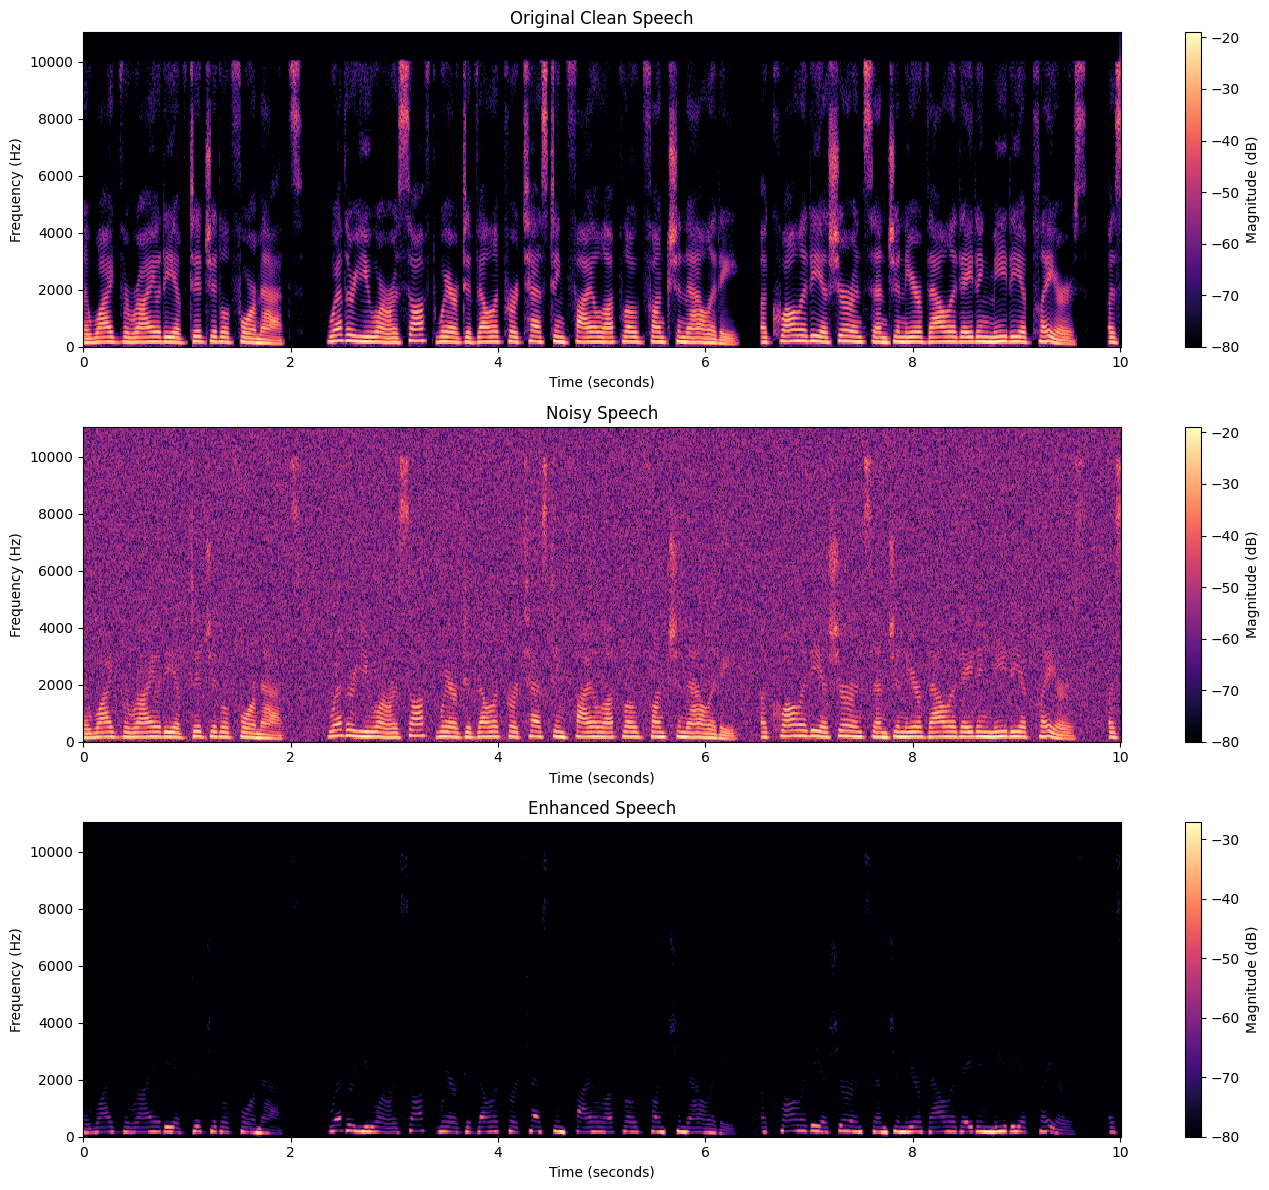

In [30]:
fig, axes = plt.subplots(
    3, 1,
    figsize=(14, 12)
)

plt.sca(axes[0])

plot_spectrogram(
    clean_speech,
    fs,
    "Original Clean Speech"
)

plt.sca(axes[1])

plot_spectrogram(
    noisy_speech,
    fs,
    "Noisy Speech"
)

plt.sca(axes[2])

plot_spectrogram(
    enhanced_speech,
    fs,
    "Enhanced Speech"
)

plt.tight_layout()
plt.show()

In [31]:
# Evaluate Improvement
def reference_snr(clean, estimate):

    residual = estimate - clean

    signal_power = np.mean(clean ** 2)
    residual_power = np.mean(residual ** 2)

    return 10 * np.log10(
        signal_power / (residual_power + 1e-12)
    )

In [32]:
input_snr = reference_snr(
    clean_speech,
    noisy_speech
)

output_snr = reference_snr(
    clean_speech,
    enhanced_speech
)

print("Input SNR:", input_snr, "dB")
print("Output SNR:", output_snr, "dB")

print(
    "SNR Improvement:",
    output_snr - input_snr,
    "dB"
)

Input SNR: 9.99999999603499 dB
Output SNR: 0.9172640112389601 dB
SNR Improvement: -9.082735984796031 dB


In [33]:
# Compare Peak and RMS Normalization

def peak_normalize(audio, target_peak=0.9):

    peak = np.max(np.abs(audio))

    if peak == 0:
        return audio.copy()

    return audio * target_peak / peak


def rms_normalize(audio, target_rms=0.1):

    rms = np.sqrt(np.mean(audio ** 2))

    if rms == 0:
        return audio.copy()

    return audio * target_rms / rms

In [34]:
peak_audio = peak_normalize(clean_speech)

rms_audio = rms_normalize(clean_speech)

In [35]:
print("Original")
display(Audio(clean_speech, rate=fs))

print("Peak normalized")
display(Audio(peak_audio, rate=fs))

print("RMS normalized")
display(Audio(rms_audio, rate=fs))

Original


Peak normalized


RMS normalized
